In [29]:
# Importing the ncessary modules
from PLsim.otf import OTF
from PLsim.scene import Scene, SceneProjector
from PLsim.system.device import Device

import hcipy as hc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import pandas as pd

# Formatting the plots
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

## Creating the photonic lantern

In [30]:
# Pixels in pupil grid (65 is enough for a 6-port PL)
ndim = 65

# Diameter of telescope aperture for pupil
diameter = 10 # [m]

# Create the pupil grid
pupil_grid = hc.make_pupil_grid(ndim, diameter)
print(pupil_grid)

# Resolution of focal grid (make sure this samples LP modes enough but also not truncate the outer parts)
focal_plane_resolution = 1e-6 # [m]

# Focal length of telescope (initial value, OTF.from_fiber_params will find an optimal focal ratio)
focal_length = 40 # [m]

# Create the focal grid
focal_grid = hc.make_pupil_grid(ndim, focal_plane_resolution * ndim)
print(focal_grid)

# Index of refraction of the core
n_core = 1.444

# Index of refraction of the cladding
n_clad = 1.444 - 5.5e-3

# Core radius
r_core = 10e-6 # [m]

# Reference wavelength of light
ref_wavelength = 1.55e-6 # [m]

print(f'n_core: {n_core}')
print(f'n_clad: {n_clad}')
print(f'r_core: {r_core}')
print(f'ref_wavelength: {ref_wavelength}')

# Telescope aperture (circular) (a binary mask that has ones inside the aperture and zeros outside)
aperture = hc.make_circular_aperture(diameter)(pupil_grid)
print(aperture)

# Creating the optical transfer function (OTF)
otf = OTF.from_fiber_params(
    n_core, n_clad, r_core, ref_wavelength,
    focal_grid, pupil_grid,
    focal_length, aperture,
    optimize_focal_length=False
)
print(otf)

# Computing OTF
otf.compute()

# Importing the function for generating a unitary matrix
from PLsim.system.lantern import generate_unitary_matrix

# Define number of wavelength channels
n_spec = 100

# Initializing matrix (complex)
matrix = generate_unitary_matrix(6)[np.newaxis, :, :].repeat(n_spec, axis=0)
print(matrix.shape)

# Initializing device with the unitary matrix
device = Device(matrix)

# Defining scene
scene = Scene(pupil_grid, ref_wavelength)

# Creating a projection onto the OTF
scene_projector = SceneProjector(otf, scene)

CartesianGrid(RegularCoords)
CartesianGrid(RegularCoords)
n_core: 1.444
n_clad: 1.4385
r_core: 1e-05
ref_wavelength: 1.55e-06
[0. 0. 0. ... 0. 0. 0.]
Supported modes:  ['LP01', 'LP11a', 'LP11b', 'LP21a', 'LP21b', 'LP02']
Number of modes:  6
(100, 6, 6)
Device initialized with:
  Lantern matrices: (100, 6, 6)
  PIC matrices: None
  Wavelengths: 100


## Creating the input scene for a binary star
- Use Herbig Ae/Be stars
- Assume an absorption line for Pa $\beta$
- Use semimajor axis range of 1 to 100 AU
- Assume a distance to CoM of 10 pc

### First, defining distances and finding projected separations

In [31]:
# Distance to CoM
d = 10 # [pc]

# Semimajor axis range
a_min = 1 # [AU]
a_max = 100 # [AU]
a_range = np.linspace(a_min, a_max, 100)

# Projected separations
theta_range = a_range / d * 1e3 # [mas]

### Next, creating spectra

Using mass-luminosity relations to get the relative flux between the two stars...

For lower main sequence ($M_\star < 2~M_\odot$):
$$
    \frac{F_1}{F_2} = \left(\frac{M_1}{M_2}\right)^5
$$
and
$$
    \frac{R_1}{R_2} = \left(\frac{M_1}{M_2}\right)^{0.9}
$$

For upper main sequence ($M_\star > 2~M_\odot$):
$$
    \frac{F_1}{F_2} = \left(\frac{M_1}{M_2}\right)^3
$$
and
$$
    \frac{R_1}{R_2} = \left(\frac{M_1}{M_2}\right)^{0.6}
$$

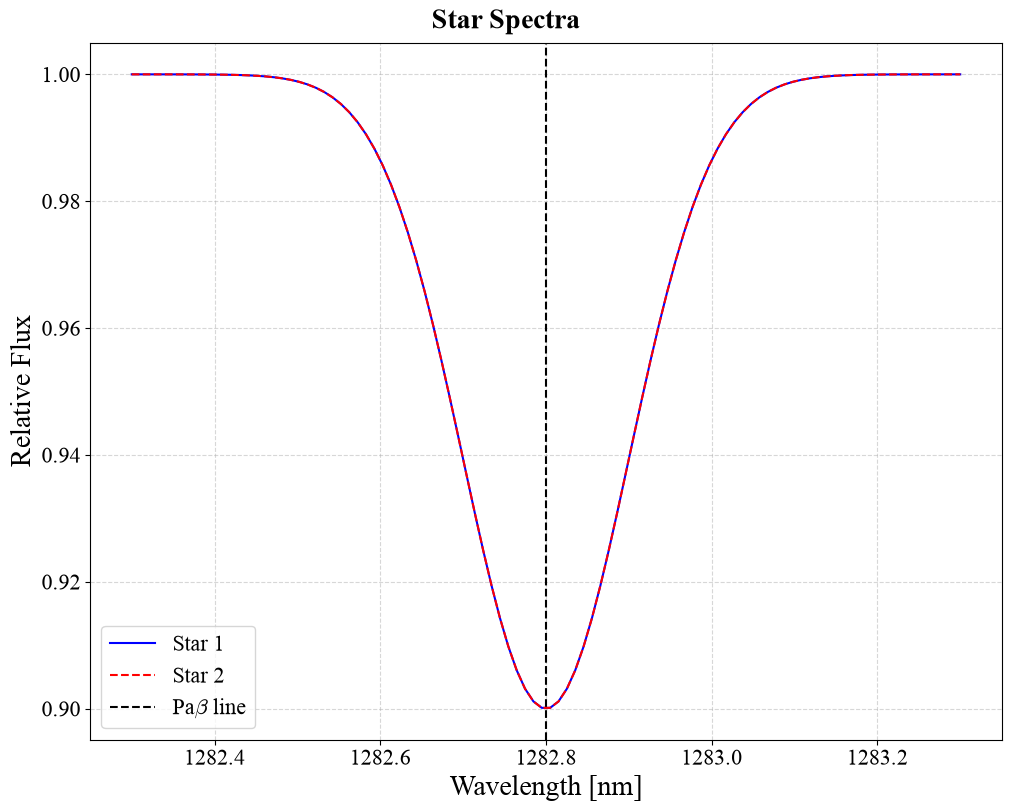

In [51]:
# Defining the mass-luminosity relation
def M_L_relation(M_1, M_2):
    if M_1 < 2:
        return (M_1/M_2)**5
    else:
        return (M_1/M_2)**3

# Wavelength range
wav_middle = 1282.8 # [nm], Paschen beta line
line_width = 0.1 # [nm], Width of the line
band_width = 10*line_width # [nm], Width of the band
wav_range = np.linspace(wav_middle - band_width/2, wav_middle + band_width/2, n_spec)

# Mass of the stars
M_1 = 1 # [M_sun]
M_2 = 1 # [M_sun]

# Flux of the continuum of star 1
F_1 = 1

# Flux of star 2
F_2 = F_1 / M_L_relation(M_1, M_2)

# Flux multiplier of the line
a_line_1 = 0.9 # Paschen beta line is 90% of the continuum normally...
a_line_2 = 0.9 # Paschen beta line is 90% of the continuum normally...

# Flux of the line of star 1
F_line_1 = a_line_1 * F_1

# Flux of the line of star 2
F_line_2 = a_line_2 * F_2

# Spectrum of star 1
star1_spectrum = F_1 * np.ones_like(wav_range)
star1_spectrum -= (F_1 - F_line_1) * np.exp(-0.5 * (wav_range - wav_middle)**2 / line_width**2)

# Spectrum of star 2
star2_spectrum = F_2 * np.ones_like(wav_range)
star2_spectrum -= (F_2 - F_line_2) * np.exp(-0.5 * (wav_range - wav_middle)**2 / line_width**2)

# Plotting the spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Star Spectra')

ax.plot(wav_range, star1_spectrum, label='Star 1', color='b', linestyle='-')
ax.plot(wav_range, star2_spectrum, label='Star 2', color='r', linestyle='--')

ax.axvline(wav_middle, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

### Applying a normalization scheme:
1. Calculate the continuum intensity for every output (far away from any spectral features):
$$
    I_{n, \text{cont}} \equiv \lim_{\lambda \to \infty} I_{n, \lambda}
$$

2. Divide all output intensities by one of the output intensities:
$$
    I_{n, \text{norm}} = \frac{I_{n, \lambda}}{I_{0, \lambda}}
$$

3. Calculate the integral to find a single number for the total normalized intensity at each output:
$$
    I_{n, \text{tot}} \equiv \left| \int{\left[I_{n, \text{norm}} - \frac{I_{n, \text{cont}}}{I_{0, \lambda}}\right] d\lambda} \right|
$$

## Testing one star position first

In [60]:
# Star 1 position
star1_x, star1_y = 0, 0 # [mas]

# Star 2 position
star2_x, star2_y = 15, 0 # [mas]

# Converting positions into radians
star1_x_rad = star1_x * 1e-3/206265 # [rad]
star1_y_rad = star1_y * 1e-3/206265 # [rad]

star2_x_rad = star2_x * 1e-3/206265 # [rad]
star2_y_rad = star2_y * 1e-3/206265 # [rad]

# Projecting the star onto the OTF
star1_projected = scene_projector.compute_point(star1_x_rad, star1_y_rad).repeat(n_spec, axis=2) * star1_spectrum[np.newaxis, np.newaxis]
star2_projected = scene_projector.compute_point(star2_x_rad, star2_y_rad).repeat(n_spec, axis=2) * star2_spectrum[np.newaxis, np.newaxis]

# Combining the projected star fields
combined_projected = star1_projected + star2_projected

# Passing the projected star through the device (I_{n, lambda})
star1_outputs = device.calculate_outputs(star1_projected.transpose(2, 0, 1))
star2_outputs = device.calculate_outputs(star2_projected.transpose(2, 0, 1))
combined_outputs = device.calculate_outputs(combined_projected.transpose(2, 0, 1))

# Initializing arrays to store the continuum intensities
star1_cont_outputs = []
star2_cont_outputs = []
combined_cont_outputs = []

# Initializing arrays to store the normalized intensities
star1_norm_outputs = []
star2_norm_outputs = []
combined_norm_outputs = []

# Initializing arrays to store the total normalized intensities
star1_tot_norm_outputs = []
star2_tot_norm_outputs = []
combined_tot_norm_outputs = []

# Output to normalize by
divisor_output = 0

for i in range(6):
    # Calculating the continuum intensity for every output (I_{n, cont})
    star1_cont_outputs.append( (star1_outputs[0, i] + star1_outputs[1, i]) / 2 )
    star2_cont_outputs.append( (star2_outputs[0, i] + star2_outputs[1, i]) / 2 )
    combined_cont_outputs.append( (combined_outputs[0, i] + combined_outputs[1, i]) / 2 )

    # Dividing all output intensities by one of the output intensities:
    star1_norm_outputs.append(star1_outputs[:, i] / star1_outputs[:, divisor_output])
    star2_norm_outputs.append(star2_outputs[:, i] / star2_outputs[:, divisor_output])
    combined_norm_outputs.append(combined_outputs[:, i] / combined_outputs[:, divisor_output])

    # Calculating the total normalized intensity for every output (I_{n, tot})
    integral1 = np.abs(np.sum( (star1_norm_outputs[i] - star1_cont_outputs[i] / star1_outputs[:, divisor_output]) * (wav_range[1] - wav_range[0]) ))
    integral2 = np.abs(np.sum( (star2_norm_outputs[i] - star2_cont_outputs[i] / star2_outputs[:, divisor_output]) * (wav_range[1] - wav_range[0]) ))
    integral3 = np.abs(np.sum( (combined_norm_outputs[i] - combined_cont_outputs[i] / combined_outputs[:, divisor_output]) * (wav_range[1] - wav_range[0]) ))

    star1_tot_norm_outputs.append(integral1)
    star2_tot_norm_outputs.append(integral2)
    combined_tot_norm_outputs.append(integral3)
    
star1_cont_outputs = np.array(star1_cont_outputs)
star2_cont_outputs = np.array(star2_cont_outputs)
combined_cont_outputs = np.array(combined_cont_outputs)

star1_norm_outputs = np.array(star1_norm_outputs)
star2_norm_outputs = np.array(star2_norm_outputs)
combined_norm_outputs = np.array(combined_norm_outputs)

star1_tot_norm_outputs = np.array(star1_tot_norm_outputs)
star2_tot_norm_outputs = np.array(star2_tot_norm_outputs)
combined_tot_norm_outputs = np.array(combined_tot_norm_outputs)

print(combined_tot_norm_outputs.shape)
print(combined_tot_norm_outputs)

(6,)
[0.0269967  0.16638854 0.1228017  0.74404156 0.07347068 0.82168622]


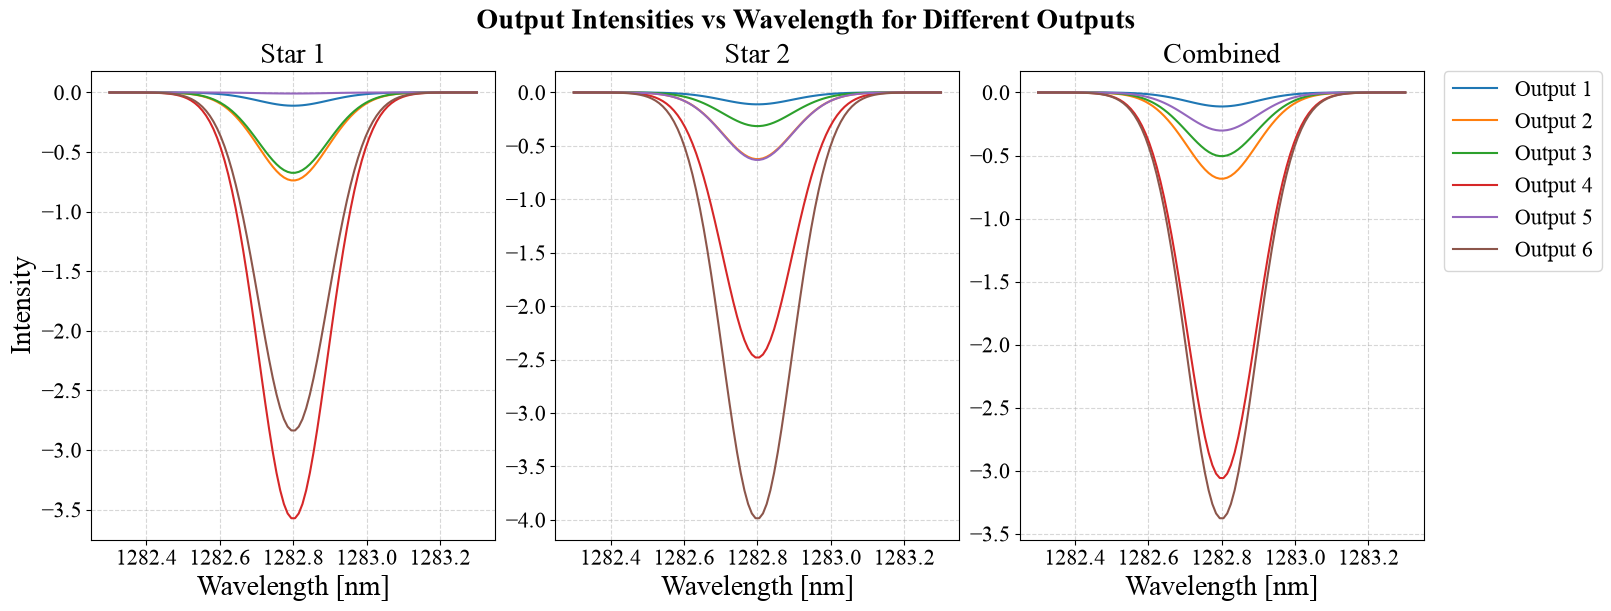

In [61]:
# Plotting the outputs
fig = plt.figure(figsize=(16, 6))
fig.set_constrained_layout(True)
axes = fig.subplots(ncols=3)

fig.suptitle('Output Intensities vs Wavelength for Different Outputs')

for i in range(6):
    axes[0].plot(wav_range, star1_outputs[:, i]/star1_outputs[:, divisor_output] - star1_cont_outputs[i]/star1_outputs[:, divisor_output], label=f'Output {i+1}')
    axes[1].plot(wav_range, star2_outputs[:, i]/star2_outputs[:, divisor_output] - star2_cont_outputs[i]/star2_outputs[:, divisor_output], label=f'Output {i+1}')
    axes[2].plot(wav_range, combined_outputs[:, i]/combined_outputs[:, divisor_output] - combined_cont_outputs[i]/combined_outputs[:, divisor_output], label=f'Output {i+1}')

axes[0].set_title('Star 1')
axes[1].set_title('Star 2')
axes[2].set_title('Combined')

axes[0].set_xlabel('Wavelength [nm]')
axes[1].set_xlabel('Wavelength [nm]')
axes[2].set_xlabel('Wavelength [nm]')

axes[0].set_ylabel('Intensity')

axes[2].legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

axes[0].grid(True, linestyle='--', alpha=0.5)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[2].grid(True, linestyle='--', alpha=0.5)
plt.show()

## Passing spectra through lantern for all star positions

In [34]:
# Converting angular separations into radians
theta_range_rad = theta_range * 1e-3/206265 # [rad]

# Star 1 position
star1_x = np.zeros_like(theta_range_rad)
star1_y = np.zeros_like(theta_range_rad)

# Star 2 position
star2_x = np.zeros_like(theta_range_rad)
star2_y = theta_range_rad

# Initializing arrays to store the mean intensities
star1_normalized_intensities = []
star2_normalized_intensities = []
combined_normalized_intensities = []

# Storing the total intensities for each output for the combined star field
combined_total_intensities = []

# Iterating through positions
for i in range(len(star1_x)):

    # Projecting the star onto the OTF
    star1_projected = scene_projector.compute_point(star1_x[i], star1_y[i]).repeat(n_spec, axis=2) * star1_spectrum[np.newaxis, np.newaxis]
    star2_projected = scene_projector.compute_point(star2_x[i], star2_y[i]).repeat(n_spec, axis=2) * star2_spectrum[np.newaxis, np.newaxis]

    # Combining the projected star fields
    combined_projected = star1_projected + star2_projected

    # Passing the projected star through the device
    star1_outputs = device.calculate_outputs(star1_projected.transpose(2, 0, 1))
    star2_outputs = device.calculate_outputs(star2_projected.transpose(2, 0, 1))

    # Passing the combined projected star through the device
    combined_outputs = device.calculate_outputs(combined_projected.transpose(2, 0, 1))

    # Calculating the mean intensity of the outputs
    constant_star1_pos = []
    constant_star2_pos = []
    constant_combined_pos = []
    
    for output in range(6):
        constant_star1_pos.append(np.mean(star1_outputs[:, output] / np.sum(star1_outputs, axis=1)))
        constant_star2_pos.append(np.mean(star2_outputs[:, output] / np.sum(star2_outputs, axis=1)))
        constant_combined_pos.append(np.mean(combined_outputs[:, output] / np.sum(combined_outputs, axis=1)))

    star1_normalized_intensities.append(constant_star1_pos) 
    star2_normalized_intensities.append(constant_star2_pos)
    combined_normalized_intensities.append(constant_combined_pos)

    combined_total_intensities.append(combined_outputs)

star1_normalized_intensities = np.array(star1_normalized_intensities)
star2_normalized_intensities = np.array(star2_normalized_intensities)
combined_normalized_intensities = np.array(combined_normalized_intensities)

combined_total_intensities = np.array(combined_total_intensities)

print(star1_normalized_intensities.shape)
print(star2_normalized_intensities.shape)
print(combined_normalized_intensities.shape)

print(combined_total_intensities.shape)

(100, 6)
(100, 6)
(100, 6)
(100, 100, 6)


### Plotting normalized outputs as a function of position

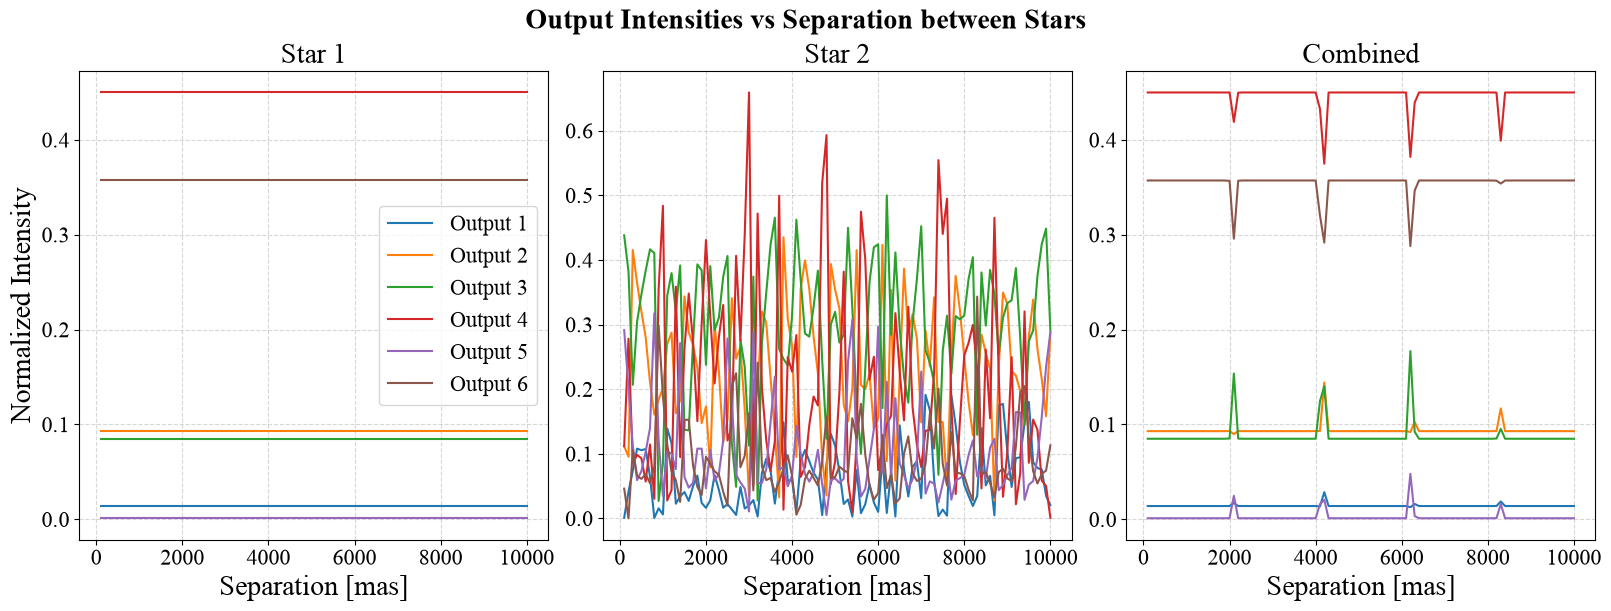

In [35]:
fig = plt.figure(figsize=(16, 6))
fig.set_constrained_layout(True)
axes = fig.subplots(ncols=3)

fig.suptitle('Output Intensities vs Separation between Stars')

axes[0].set_title('Star 1')
axes[1].set_title('Star 2')
axes[2].set_title('Combined')

for i in range(6):
    axes[0].plot(theta_range, star1_normalized_intensities[:, i], label=f'Output {i+1}')
    axes[1].plot(theta_range, star2_normalized_intensities[:, i], label=f'Output {i+1}')
    axes[2].plot(theta_range, combined_normalized_intensities[:, i], label=f'Output {i+1}')

axes[0].set_xlabel('Separation [mas]')
axes[0].set_ylabel('Normalized Intensity')

axes[1].set_xlabel('Separation [mas]')
# axes[1].set_ylabel('Normalized Intensity')

axes[2].set_xlabel('Separation [mas]')
# axes[2].set_ylabel('Normalized Intensity')

axes[0].legend()

axes[0].grid(True, linestyle='--', alpha=0.5)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.show()

### Plotting the outputs together

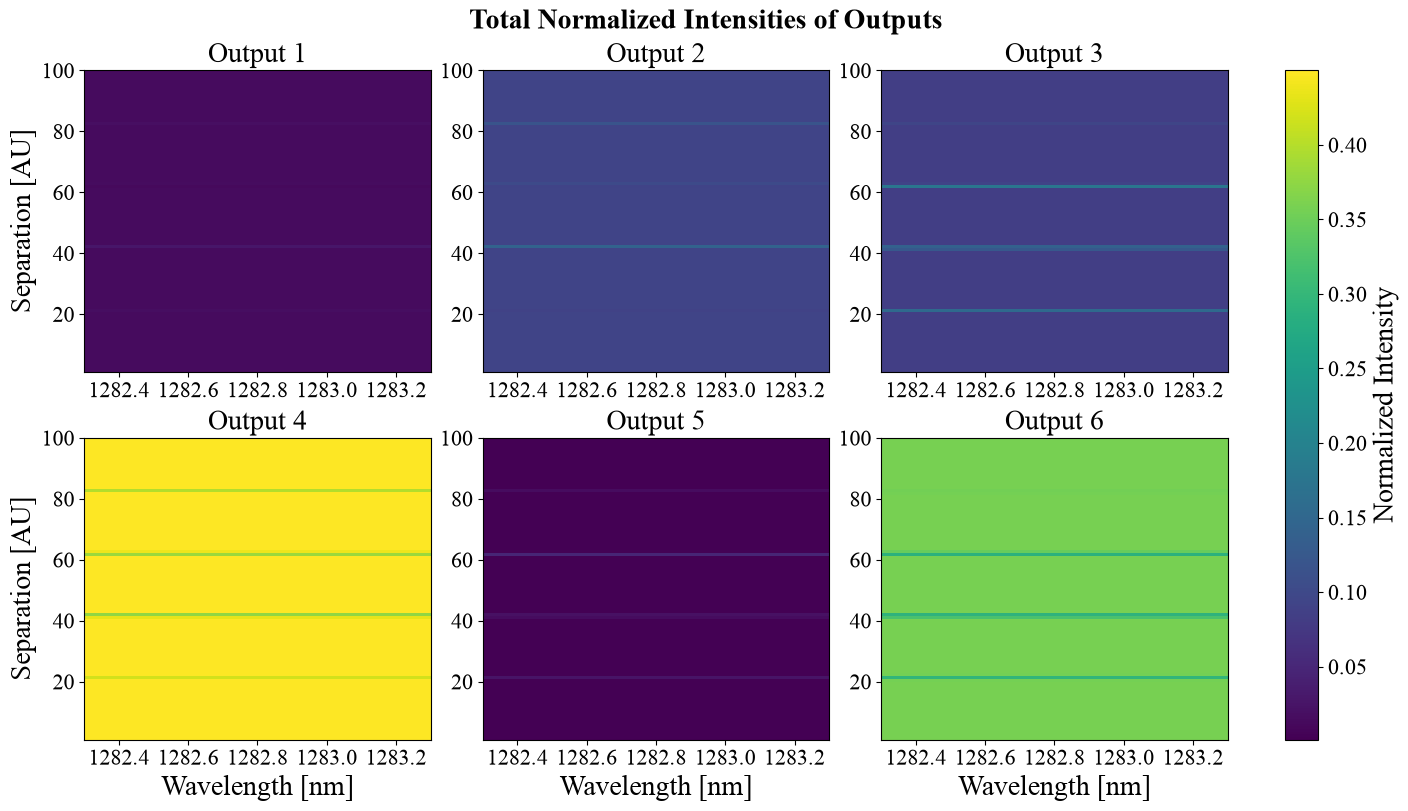

In [36]:
fig = plt.figure(figsize=(14, 8))
fig.set_constrained_layout(True)
axes = fig.subplots(nrows=2, ncols=3)

axes = axes.flatten()

fig.suptitle('Total Normalized Intensities of Outputs')

# Normalizing the total intensities by the intensity of the first output
normalized_total_intensities = combined_total_intensities / np.sum(combined_total_intensities, axis=2)[:, :, np.newaxis]

max_intensity = np.max(normalized_total_intensities)
min_intensity = np.min(normalized_total_intensities)

for i in range(6):
    axes[i].set_title(f'Output {i+1}')

    im = axes[i].imshow(normalized_total_intensities[:, :, i],
                   extent=[wav_range[0], wav_range[-1], a_min, a_max],
                   aspect='auto', origin='lower', vmin=min_intensity, vmax=max_intensity)
    
    axes[i].set_xlim(wav_range[0], wav_range[-1])
    axes[i].set_ylim(a_min, a_max)

    if i == 0 or i == 3:
        axes[i].set_ylabel('Separation [AU]')
    
    if i in [3, 4, 5]:
        axes[i].set_xlabel('Wavelength [nm]')

fig.colorbar(im, ax=axes, location='right', label='Normalized Intensity')

plt.show()